# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name: Krishna Lund**
- **Student ID: 023-24-0271**
- **Section: H**
- **GitHub: https://github.com/Krishnalund/machine-learning-practical-work**
- **Kaggle: https://www.kaggle.com/krishnalund18**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
# YOUR CODE HERE
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'})
print(df.shape)
print("Missing:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print(df['Gender'].value_counts())
df[['Age', 'Income', 'Spending']].describe().round(2)

(200, 5)
Missing: 0
Duplicates: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


**Interpretation:**
The dataset contains 200 customers and 5 columns. There are no missing values or duplicate rows, so no cleaning is needed. It has 112 women (56%) and 88 men (44%).The average Age is 38.85, Income is 60.56`k$`, and Spending Score is 50.20. Their means and medians are close, so there is no strong skew. Income has the widest range (15–137`k$`), with a few very high earners.
Income and Spending have similar standard deviations (26.26 and 25.82), so neither dominates K-Means distance. Age has a smaller standard deviation (13.97), so scaling is important when adding Age.


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


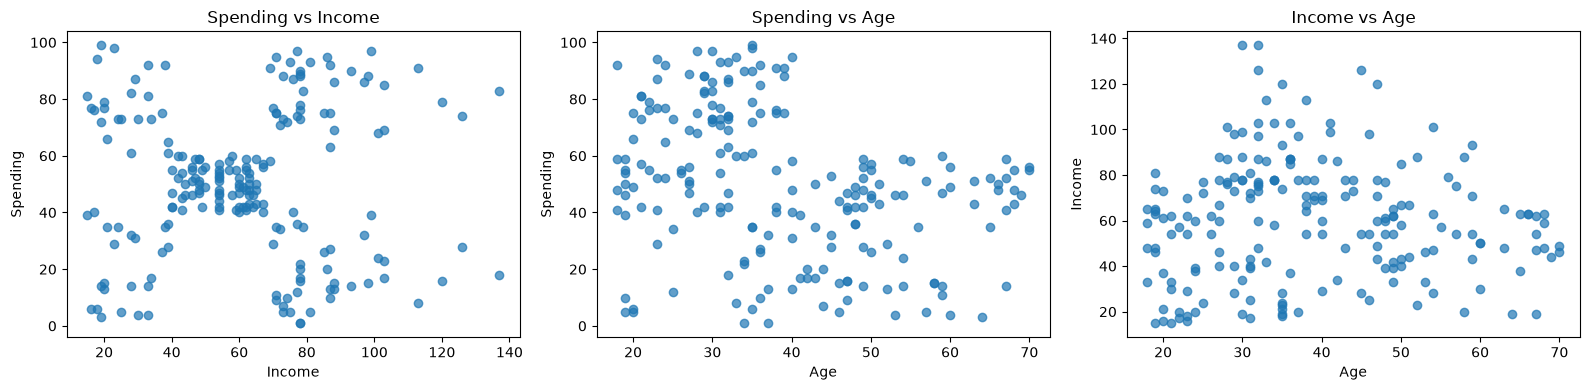

In [3]:
# YOUR CODE HERE
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (x, y) in zip(ax, [('Income', 'Spending'), ('Age', 'Spending'), ('Age', 'Income')]):
    a.scatter(df[x], df[y], alpha=.7)
    a.set_xlabel(x); a.set_ylabel(y); a.set_title(f'{y} vs {x}')
plt.tight_layout(); plt.show()

**Interpretation:**
- Spending vs Income: Shows five clear groups: one in the centre, two with low income (high and low spending) and two with high income (high and low spending).
- Spending vs Age: no clear groups, only 2–3 loose patterns. Younger customers have mixed spending, older ones mostly medium.
- Income vs Age: No clear groups. Income is spread across all ages, with the highest incomes mostly between ages 28 and 45.
- Income and Spending show the clearest five customer groups, so they are selected for K-Means clustering.

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) Spending vs Income shows about 5 clear groups, so it is the clearest plot. Spending vs Age shows 2–3 loose groups, and Income vs Age shows no clear groups, just a cloud.

(b) there is no label column, there are no actual values to compare the predictions against, so accuracy cannot be calculated. A train/test split is also unnecessary because clustering does not learn to predict a target. Instead, clustering is evaluated using compactness and separation. Compactness means how close the data points are to each other within the same cluster, while separation means how far apart different clusters are from each other. Good clustering produces groups whose points are close together and whose groups are clearly separated.






---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], float)
m = np.array([4., 11.])
it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])
    lab = dist.argmin(axis=1)
    new_m = np.array([x[lab == k].mean() for k in range(2)])
    print(f"Iter {it}: C1={x[lab==0]}  C2={x[lab==1]}  new centroids={new_m}")
    if np.allclose(new_m, m): break
    m = new_m
print("Final centroids:", m, "Inertia:", ((x - m[lab])**2).sum())

Iter 1: C1=[2. 4. 3.]  C2=[10. 12. 20. 30. 11. 25.]  new centroids=[ 3. 18.]
Iter 2: C1=[ 2.  4. 10.  3.]  C2=[12. 20. 30. 11. 25.]  new centroids=[ 4.75 19.6 ]
Iter 3: C1=[ 2.  4. 10. 12.  3. 11.]  C2=[20. 30. 25.]  new centroids=[ 7. 25.]
Iter 4: C1=[ 2.  4. 10. 12.  3. 11.]  C2=[20. 30. 25.]  new centroids=[ 7. 25.]
Final centroids: [ 7. 25.] Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
# YOUR CODE HERE
P = np.array([[185,72],[170,56],[168,60],[179,68],[182,72],[188,77]], float)
C = P[[0, 1]].copy()
for it in range(1, 20):
    d = np.sqrt(((P[:, None, :] - C[None, :, :])**2).sum(axis=2))
    lab = d.argmin(axis=1)
    newC = np.array([P[lab == k].mean(axis=0) for k in range(2)])
    print(f"Iter {it}: clusters={lab+1}, centroids={newC.round(2).tolist()}")
    if it == 1: print("Distance table iter 1:\n", d.round(2))
    if np.allclose(newC, C): break
    C = newC
print("Final distance table:\n", d.round(2))
print("By hand d(P3,M2):", np.sqrt((168-170)**2 + (60-56)**2).round(2))

Iter 1: clusters=[1 2 2 1 1 1], centroids=[[183.5, 72.25], [169.0, 58.0]]
Distance table iter 1:
 [[ 0.   21.93]
 [21.93  0.  ]
 [20.81  4.47]
 [ 7.21 15.  ]
 [ 3.   20.  ]
 [ 5.83 27.66]]
Iter 2: clusters=[1 2 2 1 1 1], centroids=[[183.5, 72.25], [169.0, 58.0]]
Final distance table:
 [[ 1.52 21.26]
 [21.13  2.24]
 [19.76  2.24]
 [ 6.19 14.14]
 [ 1.52 19.1 ]
 [ 6.54 26.87]]
By hand d(P3,M2): 4.47


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [6]:
# YOUR CODE HERE
import numpy as np

def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, float)
    if X.ndim == 1:                      
        X = X[:, None]
    C = np.asarray(init_centroids, float).copy()
    if C.ndim == 1:
        C = C[:, None]
    K = len(C)

    for it in range(1, max_iter + 1):
        d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
        labels = d.argmin(axis=1)

        new_C = C.copy()
        for k in range(K):
            if (labels == k).any():     
                new_C[k] = X[labels == k].mean(axis=0)

        if np.allclose(new_C, C):
            break
        C = new_C

    inertia = ((X - C[labels]) ** 2).sum()
    return labels, C, inertia, it

In [7]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], float)
labels, centroids, inertia, n_iter = my_kmeans(x, [4, 11])

print("Labels    :", labels)
print("Centroids :", centroids.ravel())
print("Inertia   :", inertia)
print("Iterations:", n_iter)

Labels    : [0 0 0 0 0 1 1 0 1]
Centroids : [ 7. 25.]
Inertia   : 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [8]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values.astype(float)
init5 = X2[:5].copy()
lab_m, C_m, in_m, it_m = my_kmeans(X2, init5)
km = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm='lloyd').fit(X2)
print("Iterations:", it_m, km.n_iter_)
print("Inertia   :", in_m, km.inertia_)
print("Labels equal   :", np.array_equal(lab_m, km.labels_))
print("Centroids equal:", np.allclose(C_m, km.cluster_centers_))

Iterations: 4 4
Inertia   : 44448.45544793371 44448.45544793371
Labels equal   : True
Centroids equal: True


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) Initially, point 10 was closer to centroid 11, so it belonged to C2. After iteration 1, the centroids became 3 and 18. Now, point 10 is 7 units away from C1 and 8 units away from C2. Since it is closer to C1, it moves to C1.

(b) The loop stops when no points change their clusters. It is guaranteed to stop because each iteration reduces or maintains inertia, and there are only a finite number of possible cluster assignments. However, the final result may be a local minimum, not the best possible solution, because it depends on the initial centroids.

(c) Yes. Both functions produced the same labels, centroids, inertia (44448.4554), and iteration count (4). This happened because both used the same initial centroids

(d) A centroid represents the average customer in a cluster. For example, a centroid with income 86.5 and spending 82.1 represents customers with those average values. It does not have to represent an actual customer. Features must be numeric because K-Means calculates averages and distances mathematically.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


    K     Inertia  Silhouette
0   2  181363.596       0.297
1   3  106348.373       0.468
2   4   73679.789       0.493
3   5   44448.455       0.554
4   6   37233.815       0.540
5   7   30241.344       0.529
6   8   25036.418       0.455
7   9   21916.795       0.456
8  10   20072.071       0.441
Best K by silhouette: 5


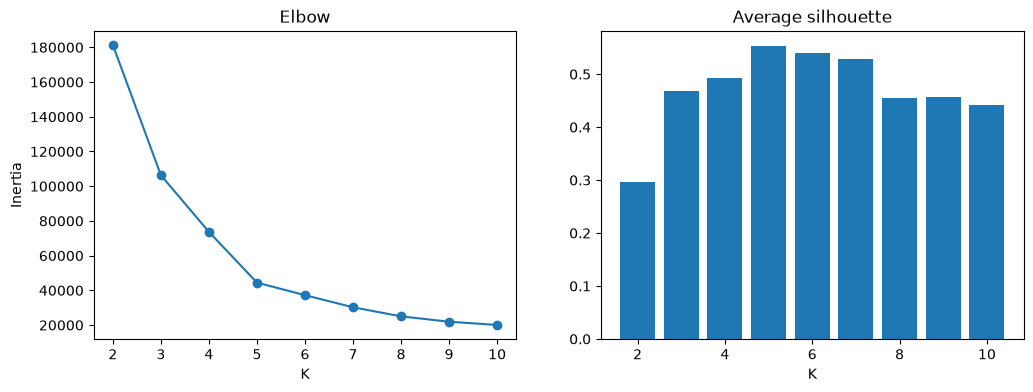

In [9]:
# YOUR CODE HERE
rows = []
for k in range(2, 11):
    m_ = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append((k, m_.inertia_, silhouette_score(X2, m_.labels_)))
tab = pd.DataFrame(rows, columns=['K', 'Inertia', 'Silhouette'])
print(tab.round(3))
print("Best K by silhouette:", tab.loc[tab.Silhouette.idxmax(), 'K'])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tab.K, tab.Inertia, 'o-'); ax[0].set_title('Elbow'); ax[0].set_xlabel('K'); ax[0].set_ylabel('Inertia')
ax[1].bar(tab.K, tab.Silhouette); ax[1].set_title('Average silhouette'); ax[1].set_xlabel('K')
plt.show()

**Interpretation:**
- Elbow Plot: Inertia drops quickly until K = 5, then improvements become small. So, the elbow is at K = 5.
- Silhouette Score: The score is highest at K = 5 (0.554), compared to K = 4 (0.493) and K = 6 (0.540). This means K = 5 gives the best-separated clusters.
- Both methods support K = 5, which also matches the five visible groups in the scatter plot. K = 6 is close, but K = 5 is simpler. We cannot choose K using the lowest inertia because inertia always decreases as K increases.

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [10]:
# YOUR CODE HERE
import numpy as np, pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples

SEED = 42
X2 = df[['Income', 'Spending']].values.astype(float)

# 1. Fit K = 5
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
labels = km5.labels_

# Silhouette of ONE point, using only NumPy distances
def sil_one(X, labels, i):
    D = np.sqrt(((X - X[i]) ** 2).sum(axis=1))       
    same = (labels == labels[i])
    same[i] = False                                  
    a = D[same].mean()                               
    b = min(D[labels == k].mean()                    
            for k in np.unique(labels) if k != labels[i])
    s = (b - a) / max(a, b)
    return a, b, s

# Customer 1 = row 0
a, b, s = sil_one(X2, labels, 0)
sil = silhouette_samples(X2, labels)
print(f"By hand       : a = {a:.2f}, b = {b:.2f}, s = {s:.4f}")
print(f"silhouette_samples: s = {sil[0]:.4f}")

# 2. Count, mean and min silhouette per cluster + negatives
summary = (pd.DataFrame({'Cluster': labels, 'Silhouette': sil})
             .groupby('Cluster')['Silhouette'].agg(['count', 'mean', 'min']).round(3))
print(summary)
print("Customers with negative silhouette:", (sil < 0).sum())

By hand       : a = 24.64, b = 42.27, s = 0.4170
silhouette_samples: s = 0.4170
         count   mean    min
Cluster                     
0           81  0.597  0.115
1           39  0.509  0.225
2           22  0.599  0.051
3           35  0.504 -0.023
4           23  0.512 -0.009
Customers with negative silhouette: 2


**Interpretation:**
For customer 1, my function gives a = 24.64, b = 42.27 and silhouette = 0.4170. Scikit-learn gives the same result, confirming my formula is correct. Since b > a, the customer is reasonably placed in its cluster.
All five clusters have average silhouettes above 0.5, meaning they are well separated. Cluster 2 (0.599) and Cluster 0 (0.597) perform best, while Cluster 3 (0.504) is weakest.
Only 2 out of 200 customers (1%) have negative scores (-0.023 and -0.009). Both are close to zero, meaning they are near cluster boundaries.
K = 5 gives good clustering results.

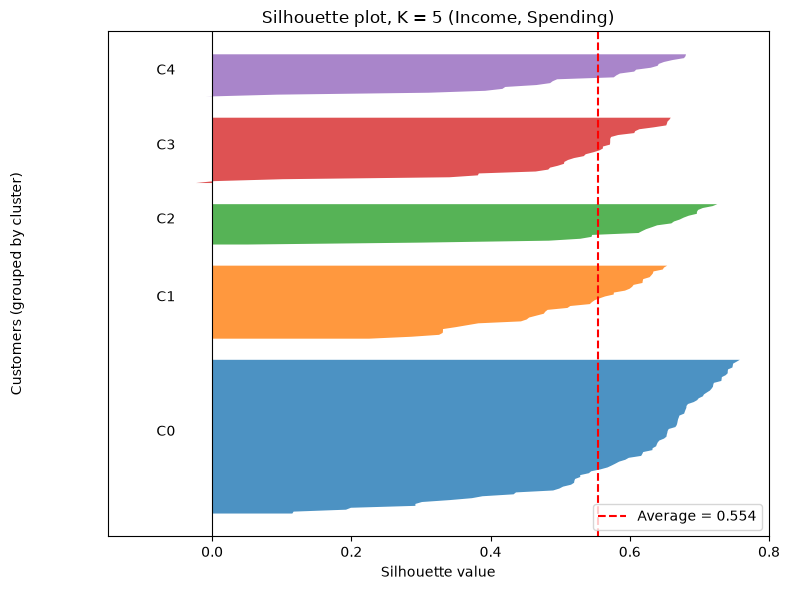

In [11]:
# YOUR CODE HERE
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
for k in range(5):
    vals = np.sort(sil[labels == k])                  
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.8)
    ax.text(-0.08, y_lower + len(vals) / 2, f'C{k}')
    y_lower = y_upper + 10

ax.axvline(sil.mean(), color='red', ls='--', label=f'Average = {sil.mean():.3f}')
ax.axvline(0, color='k', lw=0.8)                     
ax.set_xlim(-0.15, 0.8)                              
ax.set_xlabel('Silhouette value')
ax.set_ylabel('Customers (grouped by cluster)', labelpad=60)
ax.set_title('Silhouette plot, K = 5 (Income, Spending)')
ax.set_yticks([])
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Interpretation:**
Each coloured block represents a cluster, and each line represents a customer. The red dashed line shows the overall average silhouette (0.554), while the black line represents zero.
Most customers have scores between 0.4 and 0.75, meaning they are well placed. C0 is the largest cluster (81 customers), while C2 has high silhouette values. C3 and C1 have the lowest averages (0.504 and 0.509).
Only 2 customers (1%) have negative scores, meaning they are near cluster boundaries.
All five clusters have averages above 0.5, supporting K = 5.

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [12]:
# YOUR CODE HERE
pts = np.array([1, 3, 5, 7, 11, 13, 15], float)
lab, C, inertia, n = my_kmeans(pts, [1, 11])
print(lab, C.ravel(), inertia, n)
Xp = pts[:, None]; sp = silhouette_samples(Xp, lab)
for v in [1, 7, 11]:
    i = list(pts).index(v)
    print(v, np.round(sil_one(Xp, lab, i), 3), round(sp[i], 3))
print("Cluster 1:", pts[lab==0], " Cluster 2:", pts[lab==1])

[0 0 0 0 1 1 1] [ 4. 13.] 28.0 3
1 [ 4.    12.     0.667] 0.667
7 [4.    6.    0.333] 0.333
11 [3.    7.    0.571] 0.571
Cluster 1: [1. 3. 5. 7.]  Cluster 2: [11. 13. 15.]


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) The elbow suggests K = 5. Inertia drops by 29,231 from K=4 to K=5 (73,680 → 44,448). From K=5 to K=6 it drops by only 7,215 (44,448 → 37,234). After K=5 the curve flattens, which is the bend. The silhouette also suggests K = 5, because its average is highest there (0.554, against 0.540 at K=6 and 0.493 at K=4). So the two methods agree.

(b) Customer 1 has s = 0.417 (a = 24.64, b = 42.27). It is on average much closer to its own cluster than to the nearest other cluster, so it is reasonably well placed, but not deep inside its cluster (it is below the overall average of 0.554). The cluster with the weakest average silhouette is High income / Low spending (C3, mean 0.504). 2 customers have a negative silhouette: one in C3 (−0.023) and one in C4 (−0.009). Both are very close to 0, so they lie on the border between two clusters rather than being clearly misplaced.

(c) Point 7 is less well placed.
    Point 1: a = 4 and b = 12, so s = (12 − 4) / 12 = 0.667. It is much closer to its own cluster than to the other one, so it is clearly inside.
    Point 7: a = 4 and b = 6, so s = (6 − 4) / 6 = 0.333. Its distance to its own cluster is the same as for point 1, but the other cluster is only 6 away, so it sits close to the border between the two clusters.

(d) Inertia decreases as K increases and becomes 0 when K = 200 (one customer per cluster). But this creates meaningless clusters. Choose K using the Elbow Method, Silhouette Score, not just minimum inertia.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


,Setting,Distinct inertia,Lowest,Highest,% runs at best
0,"random, n_init=1",14,44448.5,91762.0,33.3
1,"k-means++, n_init=1",6,44448.5,66733.4,60.0
2,"k-means++, n_init=10",1,44448.5,44448.5,100.0


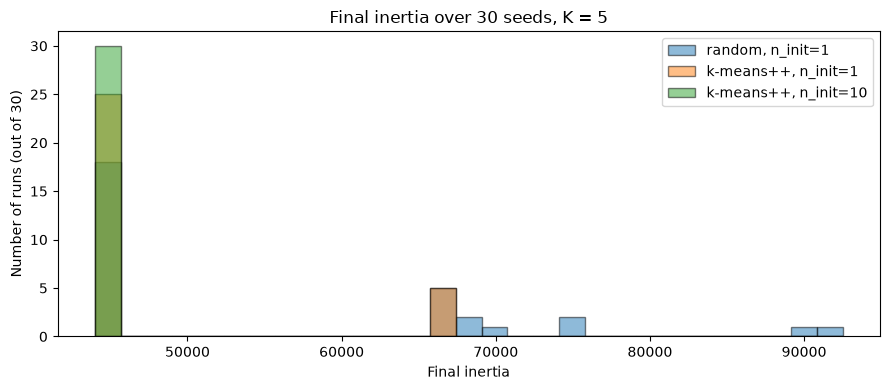

In [13]:
# YOUR CODE HERE
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

settings = {
    'random, n_init=1':     dict(init='random',    n_init=1),
    'k-means++, n_init=1':  dict(init='k-means++', n_init=1),
    'k-means++, n_init=10': dict(init='k-means++', n_init=10),
}

models = {name: [KMeans(n_clusters=5, random_state=s, **kw).fit(X2) for s in range(30)]
          for name, kw in settings.items()}
inert = {name: np.array([m.inertia_ for m in ms]) for name, ms in models.items()}
best = round(min(v.min() for v in inert.values()), 1)

rows = []
for name, v in inert.items():
    r = np.round(v, 1)
    rows.append((name, len(np.unique(r)), r.min(), r.max(), round(100 * np.mean(r == best), 1)))
table = pd.DataFrame(rows, columns=['Setting', 'Distinct inertia', 'Lowest', 'Highest', '% runs at best'])
display(table)

bins = np.linspace(44000, 92500, 30)
plt.figure(figsize=(9, 4))
for name, v in inert.items():
    plt.hist(v, bins=bins, alpha=0.5, label=name, edgecolor='k')
plt.xlabel('Final inertia'); plt.ylabel('Number of runs (out of 30)')
plt.title('Final inertia over 30 seeds, K = 5')
plt.legend(); plt.tight_layout(); plt.show()


**Interpretation:**
- Random Start: Produced 14 different inertia values. Only 33.3% of runs reached the best value, while some gave much worse results.
- K-means++ (n_init=1): Produced only 6 different values and reached the best value in 60% of runs.
- K-means++ (n_init=10): All 30 runs achieved the best inertia of 44,448.5 (100%), giving the most consistent results.
Random start reached the best value in only 33.3% of runs, and its worst run was 91,762. K-means++ with n_init=1 was better (60%) but still reached 66,733 at worst.

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


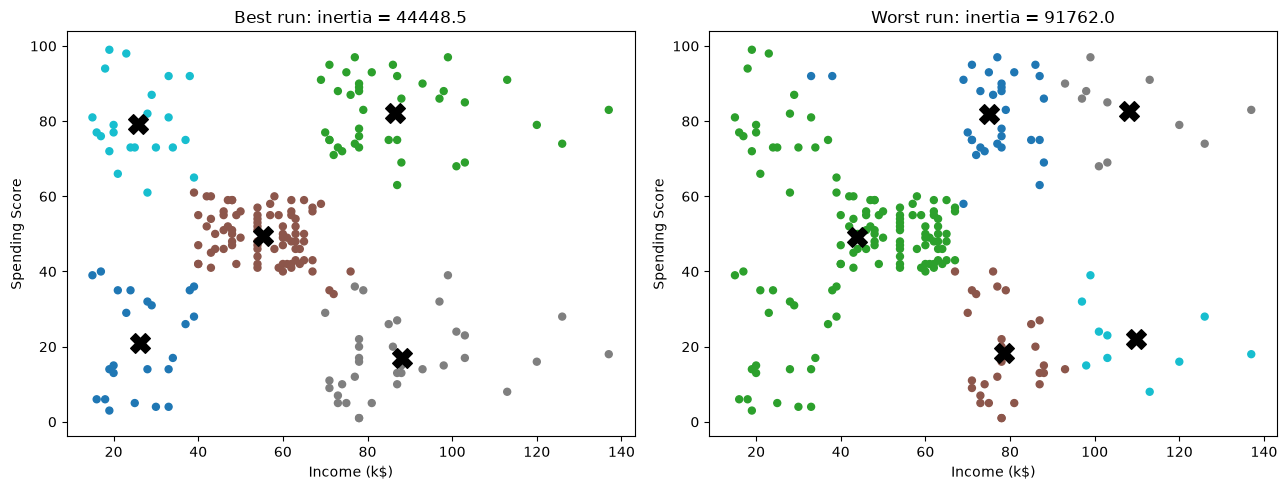

Best inertia : 44448.5
Worst inertia: 91762.0
ARI (best vs worst): 0.455


In [14]:
# YOUR CODE HERE
rand_models, rand_inert = models['random, n_init=1'], inert['random, n_init=1']
best_m, worst_m = rand_models[rand_inert.argmin()], rand_models[rand_inert.argmax()]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, m, title in zip(ax, [best_m, worst_m], ['Best run', 'Worst run']):
    a.scatter(X2[:, 0], X2[:, 1], c=m.labels_, cmap='tab10', s=25)
    a.scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], c='k', marker='X', s=200)
    a.set_title(f'{title}: inertia = {m.inertia_:.1f}')
    a.set_xlabel('Income (k$)'); a.set_ylabel('Spending Score')
plt.tight_layout(); plt.show()

print("Best inertia :", round(best_m.inertia_, 1))
print("Worst inertia:", round(worst_m.inertia_, 1))
print("ARI (best vs worst):", round(adjusted_rand_score(best_m.labels_, worst_m.labels_), 3))

**Interpretation:**
- Best Run (Inertia = 44,448.5): Correctly identifies five natural customer groups: Low/High, Low/Low, Mid/Mid, High/High and High/Low. Each centroid is placed near the centre of its group.
- Worst Run (Inertia = 91,762.0): Produces incorrect clusters. It merges three groups on the left and centre and splits the high-income customers into four clusters. This makes the inertia almost twice as high.
- ARI = 0.455: Shows that the two runs produce quite different customer groupings.

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) Random start (n_init=1) produced 14 different final inertia values (44,448.5 to 91,762.0), and only 33.3% of its runs reached the best. k-means++ (n_init=1) produced 6 values (up to 66,733.4), and 60% reached the best. k-means++ (n_init=10) produced 1 value, and 100% reached the best.

(b) K-Means improves step by step from its starting centroids and cannot escape a local minimum. Different starting points can therefore end in different local minima. In my runs the final inertia ranged from 44,448.5 to 91,762.0 for the same data and K = 5.

(c) k-means++ chooses starting centroids that are far apart, which reduced bad results (33.3% to 60% reaching the best). n_init runs several starts and keeps the lowest-inertia result. With n_init=10, all 30 seeds gave the best inertia of 44,448.5 (100%).

(d) Cluster numbers are just labels that can change between runs, so comparing them directly would call identical clusterings different. ARI compares which points are grouped together, so it ignores the numbering. ARI = 1 means the same grouping and about 0 means random agreement. My best and worst runs had ARI = 0.455, so they are quite different clusterings.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI raw k$ vs raw dollars       : 0.49
ARI scaled k$ vs scaled dollars : 1.0
ARI raw dollars vs scaled dollars: 0.36


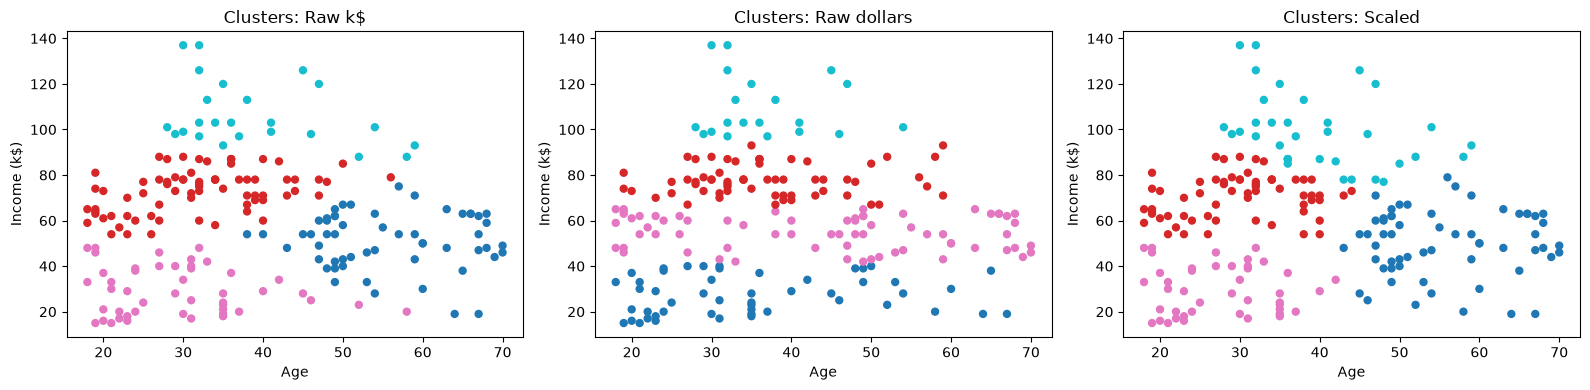

In [15]:
# YOUR CODE HERE
from sklearn.preprocessing import StandardScaler

Xk = df[['Age', 'Income']].values.astype(float)   
Xd = Xk.copy(); Xd[:, 1] = Xd[:, 1] * 1000         
Xk_s = StandardScaler().fit_transform(Xk)
Xd_s = StandardScaler().fit_transform(Xd)

def fit4(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

L = {'raw k$': fit4(Xk), 'raw dollars': fit4(Xd),
     'scaled k$': fit4(Xk_s), 'scaled dollars': fit4(Xd_s)}

print("ARI raw k$ vs raw dollars       :", round(adjusted_rand_score(L['raw k$'], L['raw dollars']), 3))
print("ARI scaled k$ vs scaled dollars :", round(adjusted_rand_score(L['scaled k$'], L['scaled dollars']), 3))
print("ARI raw dollars vs scaled dollars:", round(adjusted_rand_score(L['raw dollars'], L['scaled dollars']), 3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (title, lab) in zip(ax, [('Raw k$', L['raw k$']),
                                ('Raw dollars', L['raw dollars']),
                                ('Scaled', L['scaled k$'])]):
    a.scatter(df['Age'], df['Income'], c=lab, cmap='tab10', s=25)
    a.set_title(f'Clusters: {title}'); a.set_xlabel('Age'); a.set_ylabel('Income (k$)')
plt.tight_layout(); plt.show()

**Interpretation:**
Changing Income from `k$` to dollars changed the clusters, even though the data stayed the same. ARI = 0.49.
After scaling, both units produced exactly the same clusters (ARI = 1.0).
Raw dollars mainly grouped customers by Income because its values were much larger than Age.
Raw dollars vs scaled dollars gave ARI = 0.36, so the unscaled dollar version clusters very differently from the scaled one.
K-means uses distances, so features with larger values can dominate clustering. StandardScaler makes features comparable so Age and Income have equal influence.

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [16]:
# YOUR CODE HERE
wine = load_wine()
Xw, yw = wine.data, wine.target
print(Xw.shape, "cultivar counts:", np.bincount(yw))

sd = pd.Series(Xw.std(axis=0), index=wine.feature_names).sort_values(ascending=False)
print("Three largest std:\n", sd.head(3).round(3))
print("Smallest std:\n", sd.tail(1).round(3))

(178, 13) cultivar counts: [59 71 48]
Three largest std:
 proline              314.022
magnesium             14.242
alcalinity_of_ash      3.330
dtype: float64
Smallest std:
 nonflavanoid_phenols    0.124
dtype: float64


In [17]:
# YOUR CODE HERE
Xw_s = StandardScaler().fit_transform(Xw)

res = {}
for name, X in [('Raw', Xw), ('Scaled', Xw_s)]:
    m = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X)
    res[name] = m.labels_
    print(f"{name:7s} ARI = {adjusted_rand_score(yw, m.labels_):.3f}   "
          f"Silhouette = {silhouette_score(X, m.labels_):.3f}   "
          f"Sizes = {np.bincount(m.labels_)}")

Raw     ARI = 0.371   Silhouette = 0.571   Sizes = [62 47 69]
Scaled  ARI = 0.897   Silhouette = 0.285   Sizes = [65 51 62]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


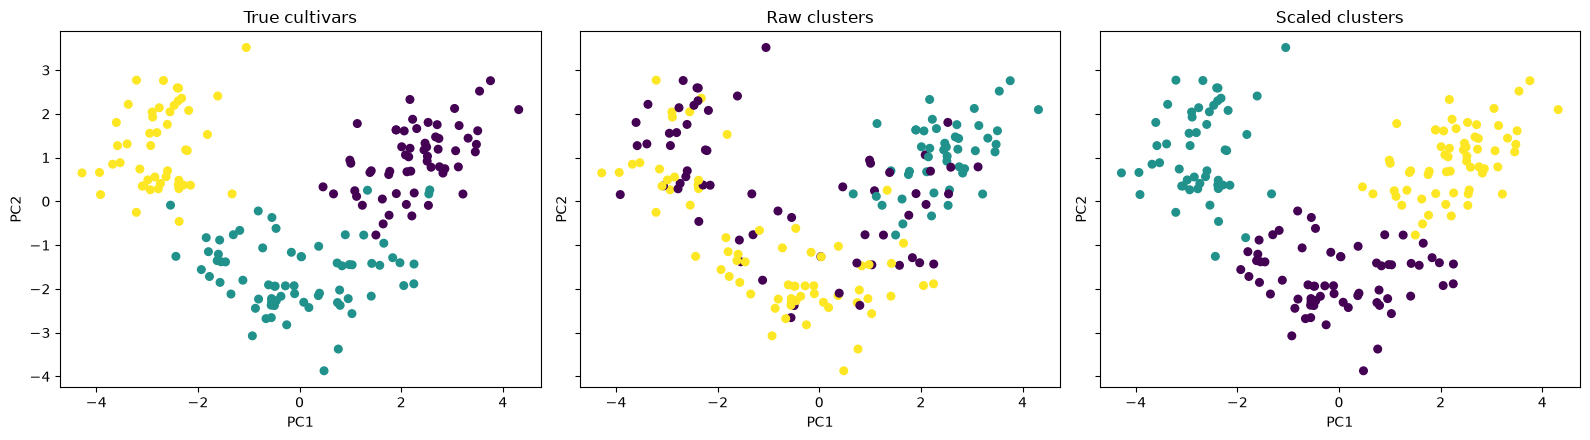

In [18]:
# YOUR CODE HERE
Z = PCA(n_components=2, random_state=SEED).fit_transform(Xw_s)  

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for a, (title, lab) in zip(ax, [('True cultivars', yw),
                                ('Raw clusters', res['Raw']),
                                ('Scaled clusters', res['Scaled'])]):
    a.scatter(Z[:, 0], Z[:, 1], c=lab, cmap='viridis', s=30)
    a.set_title(title); a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.tight_layout(); plt.show()

**Interpretation:**
- True Cultivars: Shows the original three wine groups, which are clearly separated.
- Raw Clusters: The clusters do not match the original groups. Different colours are mixed because Proline has much larger values and dominates the distance calculation.
- Scaled Clusters: The clusters closely match the true cultivars because scaling gives all 13 features equal importance.
- ARI Comparison:
- Raw clusters: 0.371 (poor match).
- Scaled clusters: 0.897 (very good match).

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) Distance formula:
\[
d=\sqrt{(\Delta Age)^2+(\Delta Income)^2}
\]

When Income changed from `k$` to dollars, its values became much larger than Age. Therefore, Income dominated the distance, and Age had very little effect.
- ARI between raw `k$` and dollars = 0.49.
- After scaling, ARI = 1.0 (same clusters).

(b) Proline dominated. Its std is 314, about 22× the next feature (magnesium, 14.2) and about 2,500× the smallest (0.124). Raw ARI = 0.371, scaled ARI = 0.897.

(c) Silhouette measures how close and separate clusters are, not whether they match the actual groups.Raw data had a higher silhouette (0.571) but poor ARI (0.371). Scaled data had a lower silhouette (0.285) but better ARI (0.897).We cannot fairly compare them because they use different distance scales.
On raw data the distance is almost entirely Proline, so the data is nearly one-dimensional and the clusters look well separated along that axis, which gives a high silhouette. Scaled data uses 13 dimensions, so clusters naturally overlap more and the silhouette is lower. Silhouettes are measured in different distance spaces, so they are not comparable.

(d) I scale whenever features have different units or their standard deviations differ by a large factor (e.g. more than about 3–5×). I check df.std() first, then confirm the clusters make business sense.

---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [19]:
# YOUR CODE HERE
extra = np.array([[400., 99.]])
X_out = np.vstack([X2, extra])                      

km_o = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)     
km_w = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out)   

for name, m in [('WITHOUT extra customer', km_o), ('WITH extra customer', km_w)]:
    c = m.cluster_centers_
    order = c[:, 0].argsort()                       
    print(name)
    print("  Sizes     :", np.bincount(m.labels_)[order])
    print("  Centroids (Income, Spending):", c[order].round(1).tolist())

ari = adjusted_rand_score(km_o.labels_, km_w.labels_[:200])   
print("\nARI on the original 200 customers:", round(ari, 3))

WITHOUT extra customer
  Sizes     : [22 23 81 39 35]
  Centroids (Income, Spending): [[25.7, 79.4], [26.3, 20.9], [55.3, 49.5], [86.5, 82.1], [88.2, 17.1]]
WITH extra customer
  Sizes     : [ 23 100  39  38   1]
  Centroids (Income, Spending): [[26.3, 20.9], [48.3, 56.5], [86.5, 82.1], [87.0, 18.6], [400.0, 99.0]]

ARI on the original 200 customers: 0.753


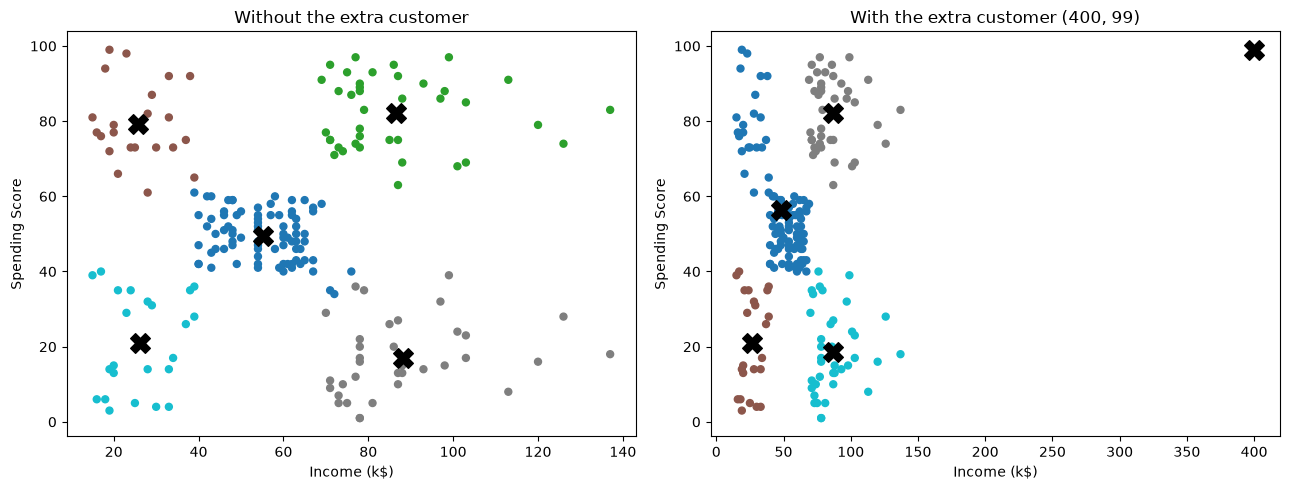

In [20]:
# YOUR CODE HERE
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(X2[:, 0], X2[:, 1], c=km_o.labels_, cmap='tab10', s=25)
ax[0].scatter(km_o.cluster_centers_[:, 0], km_o.cluster_centers_[:, 1], c='k', marker='X', s=200)
ax[0].set_title('Without the extra customer')

ax[1].scatter(X_out[:, 0], X_out[:, 1], c=km_w.labels_, cmap='tab10', s=25)
ax[1].scatter(km_w.cluster_centers_[:, 0], km_w.cluster_centers_[:, 1], c='k', marker='X', s=200)
ax[1].set_title('With the extra customer (400, 99)')

for a in ax:
    a.set_xlabel('Income (k$)'); a.set_ylabel('Spending Score')
plt.tight_layout(); plt.show()

**Interpretation:**
Without the outlier: K-means correctly identifies five customer groups with sizes 22/23/81/39/35.
With the outlier (Income = 400): The cluster sizes change to 23/100/39/38/1.
The outlier gets its own cluster (size 1), leaving only four clusters for the 200 original customers.
The Low/High and Mid/Mid groups merge into one cluster of 100 customers.
The original customers' ARI drops to 0.753, showing that the clustering has changed significantly.
K-means is sensitive to outliers because it uses distances. One extreme value can shift centroids and damage the original clusters.

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [21]:
# YOUR CODE HERE
# 1. distance of every customer to its nearest centroid (model fitted on the original 200)
d_all   = km_o.transform(X2).min(axis=1)
d_extra = km_o.transform(extra).min()

# 2. mean + 3 std rule (mean and std from the 200 real customers)
thr  = d_all.mean() + 3 * d_all.std()
flag = d_all > thr
print(f"Threshold          : {thr:.2f}")
print(f"Real customers flagged: {flag.sum()}")
print(f"Extra customer distance: {d_extra:.1f}  -> flagged: {d_extra > thr}")

# 3. the 5 real customers farthest from their centroid
top5 = (df.assign(Cluster=km_o.labels_, Distance=d_all)
          .nlargest(5, 'Distance')[['CustomerID', 'Age', 'Income', 'Spending', 'Cluster', 'Distance']]
          .round(2))
print("\n5 farthest real customers:")
display(top5)

# 4. remove flagged points, refit K = 5, compare with the original model using predict
km_clean = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[~flag])
print("\nCluster sizes after removing flagged points:", np.bincount(km_clean.labels_))
print("ARI vs original model on the 200 customers  :",
      round(adjusted_rand_score(km_o.labels_, km_clean.predict(X2)), 3))
print("Refit centroids (sorted by income):\n", km_clean.cluster_centers_[km_clean.cluster_centers_[:,0].argsort()].round(1))

Threshold          : 34.80
Real customers flagged: 4
Extra customer distance: 313.9  -> flagged: True

5 farthest real customers:


,CustomerID,Age,Income,Spending,Cluster,Distance
199,200,30,137,83,1,50.47
198,199,32,137,18,3,48.81
197,198,32,126,74,1,40.29
196,197,45,126,28,3,39.34
195,196,35,120,79,1,33.61



Cluster sizes after removing flagged points: [80 34 23 37 22]
ARI vs original model on the 200 customers  : 0.985
Refit centroids (sorted by income):
 [[25.7 79.4]
 [26.3 20.9]
 [55.1 49.7]
 [84.1 82.3]
 [85.2 17.3]]


**Interpretation:**
The Mean + 3 Std threshold is 34.80. The extra customer (400, 99) has a distance of 313.9 (9 times the threshold), so it is clearly an anomaly.
The rule also flagged 4 real customers:
- ID 200: Distance 50.47
- ID 199: Distance 48.81
- ID 198: Distance 40.29
- ID 197: Distance 39.34
All have very high incomes (126–137`k$`), making them unusual but valid customers. Two are high spenders (potential VIPs), while two spend very little. Customer 196 (distance 33.61) was not flagged because it is below the threshold.
After removing the 4 customers and refitting K = 5, cluster sizes became 80/34/23/37/22, with ARI = 0.985. This means the original clustering was almost completely restored, with only slight centroid shifts in the High/High and High/Low groups.

**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) The extreme customer (400, 99) created a separate cluster of size 1, leaving only 4 clusters for 200 customers.
- Low/High (22) merged with Mid/Mid (81), forming a cluster of 100 with centroid (48.3, 56.5).
- High/Low increased from 35 to 38, and its centroid shifted from (88.2, 17.1) to (87.0, 18.6).
- High/High and Low/Low remained unchanged.
ARI dropped to 0.753.

(b) The rule detected the extra customer successfully. Its distance (313.9) was 9 times the threshold (34.80).It also flagged 4 real customers (IDs 197–200) with incomes of 126–137k$. They are not mistakes. Two spend a lot (74, 83), while two spend little (28, 18). They are unusual customers worth investigating, possibly VIPs.

(c) 
**Two ways to handle outliers:**
1. Cap extreme values or apply log transformation.
2. Use outlier-resistant methods.
    
**Risk of deleting outliers:**
They may be genuine and valuable customers. Removing them can give an incomplete picture of the data and affect future predictions.



---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [22]:
# YOUR CODE HERE
km = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)   
df['Cluster'] = km.labels_
df['Female'] = (df['Gender'] == 'Female').astype(int)

profile = (df.groupby('Cluster')
             .agg(N=('CustomerID', 'count'),
                  Age=('Age', 'mean'),
                  Income=('Income', 'mean'),
                  Spending=('Spending', 'mean'),
                  PctFemale=('Female', lambda s: 100 * s.mean()))
             .sort_values('Income').round(1))
profile

,N,Age,Income,Spending,PctFemale
Cluster,,,,,
2,22,25.3,25.7,79.4,59.1
4,23,45.2,26.3,20.9,60.9
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
3,35,41.1,88.2,17.1,45.7


**Interpretation:**
The profile shows High/High is youngest of the high-income groups (age 32.7), Low/High is youngest overall (25.3), and Low/Low is oldest (45.2). Women are 59–61% in the low-income and Mid groups but 45.7% in High/Low.

In [23]:
# YOUR CODE HERE
def segment_name(r):
    inc = 'Low' if r['Income'] < 40 else ('High' if r['Income'] >= 70 else 'Mid')
    spe = 'Low' if r['Spending'] < 35 else ('High' if r['Spending'] >= 65 else 'Mid')
    return f'{inc} income / {spe} spending'

names = df.groupby('Cluster')[['Income', 'Spending']].mean().apply(segment_name, axis=1)
df['Segment'] = df['Cluster'].map(names)
print(df['Segment'].value_counts())

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


**Interpretation:**
The largest segment is Mid Income / Mid Spending with 81 customers (40.5%). High/High has 39 customers, while High/Low has 35. Low/Low has 23, and Low/High has 22. The five groups add up to 200 customers. Their rule-based names match their profiles.

### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [24]:
# YOUR CODE HERE
# 1. % of women per segment and overall
print(pd.crosstab(df['Segment'], df['Gender'], normalize='index').mul(100).round(1))
print("\nOverall % female:", round(100 * df['Female'].mean(), 1))

# 2. Scale Age, Income, Spending together, silhouette for K = 2..8
X3 = StandardScaler().fit_transform(df[['Age', 'Income', 'Spending']])
sil3 = {k: silhouette_score(X3, KMeans(k, n_init=10, random_state=SEED).fit_predict(X3))
        for k in range(2, 9)}
print("\nAverage silhouette (Age, Income, Spending, scaled):")
print(pd.Series(sil3).round(3))

Gender                       Female  Male
Segment                                  
High income / High spending    53.8  46.2
High income / Low spending     45.7  54.3
Low income / High spending     59.1  40.9
Low income / Low spending      60.9  39.1
Mid income / Mid spending      59.3  40.7

Overall % female: 56.0

Average silhouette (Age, Income, Spending, scaled):
2    0.335
3    0.358
4    0.404
5    0.417
6    0.428
7    0.417
8    0.408
dtype: float64


**Interpretation:**
Women make up 56% of customers. Gender differences across segments are small (45.7%–60.9%), so gender does not clearly separate the groups.
The silhouette score increases from 0.335 (K=2) to 0.428 (K=6), then decreases slightly. K=5 and K=7 both score 0.417, showing that scores are fairly close from K=5 to K=8.

### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [25]:
# YOUR CODE HERE
bestK = max(sil3, key=sil3.get)
km3 = KMeans(n_clusters=bestK, n_init=10, random_state=SEED).fit(X3)
df['Cluster3'] = km3.labels_
print("Best K from the silhouette table:", bestK)

profile3 = (df.groupby('Cluster3')
              .agg(N=('CustomerID', 'count'), Age=('Age', 'mean'),
                   Income=('Income', 'mean'), Spending=('Spending', 'mean'))
              .sort_values('Age').round(1))
display(profile3)

print("ARI (3-feature K=6 vs 2-feature K=5):",
      round(adjusted_rand_score(df['Cluster'], df['Cluster3']), 3))

Best K from the silhouette table: 6


,N,Age,Income,Spending
Cluster3,,,,
4,23,25.0,25.3,77.6
1,39,26.8,57.1,48.1
3,39,32.7,86.5,82.1
2,33,41.9,88.9,17.0
5,21,45.5,26.3,19.4
0,45,56.3,54.3,49.1


ARI (3-feature K=6 vs 2-feature K=5): 0.7


**Interpretation:**
Using Age, Income and Spending, the best K is 6.
Four groups remain almost the same:
- Low/High: 23 customers.
- High/High: 39 customers.
- High/Low: 33 customers.
- Low/Low: 21 customers.
The main change is that the Mid/Mid group splits into younger (39 customers, age 26.8) and older (45 customers, age 56.3) groups.
The ARI is 0.700, meaning the two segmentations are related but not identical.

**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) 
- High income / High spending: “VIP Shoppers” (39 customers, age 32.7, income 86.5`k$`, spending 82.1). Action: give them loyalty rewards and early access to new collections.
- High income / Low spending: “Untapped Affluent” (35 customers, age 41.1, income 88.2`k$`, spending 17.1). Action: send personalised premium offers and invitations to exclusive events to raise their spending.
- Mid income / Mid spending: “Core Customers” (81 customers, age 42.7, income 55.3`k$`, spending 49.5). Action: offer seasonal bundles and a points programme to keep them loyal.
- Low income / High spending: “Young Trend Seekers” (22 customers, age 25.3, income 25.7`k$`, spending 79.4). Action: offer instalment plans and discount days so they keep shopping without overspending.
- Low income / Low spending: “Price-Sensitive Savers” (23 customers, age 45.2, income 26.3`k$`, spending 20.9). Action: send low-cost clearance deals by SMS or email, with minimal marketing spend.

(b) **Most valuable:** High/High (39 customers) because they have high income (86.5`k$`) and spending (82.1).
**Biggest opportunity:** High/Low (35 customers) because they earn well (88.2`k$`) but spend very little (17.1). Increasing their spending could bring more profit.

(c) Women make up 56% of customers. Female representation across segments ranges from 45.7% to 60.9%. Only High/Low has more men (54.3%), but it has just 35 customers. Therefore, gender does not clearly separate the segments.

(d) Adding Age changes the best K from 5 to 6. The Mid/Mid group splits into younger (39 customers, age 26.8) and older (45 customers, age 56.3) groups. Other groups remain almost the same. ARI is 0.700.Silhouette scores from different feature sets cannot be directly compared. I would choose 2-feature K=5 because it is simpler, matches the five clear groups in the plot, and is easier to use for business decisions. Age can still be used as extra customer information.


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [26]:
# YOUR CODE HERE
out = df[['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']]
out.to_csv('customer_segments.csv', index=False)

print("Saved customer_segments.csv with", len(out), "rows")
print(out['Segment'].value_counts())
out.head()

Saved customer_segments.csv with 200 rows
Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,Low income / Low spending
1,2,21,Male,15,81,2,Low income / High spending
2,3,20,Female,16,6,4,Low income / Low spending
3,4,23,Female,16,77,2,Low income / High spending
4,5,31,Female,17,40,4,Low income / Low spending


**Interpretation:**
The customer_segments.csv file contains 200 customers with 7 columns: CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
The segment counts are 81 Mid/Mid, 39 High/High, 35 High/Low, 23 Low/Low and 22 Low/High. They match Part 6.
For example, customers 1, 3 and 5 belong to Low/Low, while customers 2 and 4 belong to Low/High.
Cluster contains K-Means numeric labels, while Segment contains readable names that marketing teams can easily understand and use.

**Executive Summary** (6-8 lines)
- K chosen: K = 5 using Income and Spending. It has the highest silhouette score (0.554). The elbow also shows that K = 5 is a good choice because the improvement becomes smaller after it.
- Segments: Five groups were found: Mid/Mid (81), High/High (39), High/Low (35), Low/Low (23) and Low/High (22).
- Actions: Give VIPs loyalty rewards and early access, offer premium deals to high earners who spend less, give core customers seasonal bundles, offer discounts to young budget customers, and provide low-cost deals to price-sensitive customers.
- Scaling: Income and Spending have similar ranges, so raw values were used. Scaling was used for the three-feature clustering because Age has a different scale. Part 4 showed that scaling can affect clustering results.
- Outliers: The extra customer (400, 99) disturbed the clusters and merged two real groups (ARI 0.753). The distance rule detected it (313.9 compared to the 34.8 threshold). It also flagged 4 real high-income customers. After removing them, the original clusters were almost restored (ARI 0.985).
- Limitation: The dataset contains only 200 customers from one mall and uses only two main features. The groups are not tested against actual buying behaviour and may change with more data.

**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) The most surprising result was the Wine dataset. Raw data had a higher silhouette score (0.571) than scaled data (0.285), but scaled data had much better clustering (ARI 0.897 vs 0.371). This showed that a high silhouette score does not always mean better clustering. Also, one extra customer changed the clusters significantly (ARI 0.753).

(b) With one more hour, I would:
- Test cluster stability using different customer samples.
- Add more features, such as purchase categories.
- Test whether different customer segments respond differently to marketing offers.


---